# Level 2, Task 1: Predictive Modelling (Regression)
**Codveda Technology | Data Science Internship**

**Brief Summary**

In this notebook I built a model that predicts house prices (a continuous number). I splited the data into training and testing sets, trained a linear regression model, and evaluated it with mean squared error (MSE) and R-squared. Then I traind a Decision Tree and a Random Forest and compared all three models.

## 1.0 Setting Up

### 1.1 Importing the Libraries

In [12]:
import pandas as pd                                   # load and work with the data table
import numpy as np                                    # square roots and other number work
import matplotlib.pyplot as plt                       # base plotting
import seaborn as sns                                 # heatmap and nicer charts
from sklearn.model_selection import train_test_split, cross_val_score, KFold   # split the data and cross-validate
from sklearn.preprocessing import StandardScaler      # scale the features for linear regression
from sklearn.pipeline import make_pipeline            # chain scaling and a model in one step
from sklearn.linear_model import LinearRegression     # the main model
from sklearn.tree import DecisionTreeRegressor        # comparison model 1
from sklearn.ensemble import RandomForestRegressor    # comparison model 2
from sklearn.metrics import mean_squared_error, r2_score   # the two required metrics

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

**Interpretation:** All the libraries loaded without errors. Besides the usual ones, I import three models (Linear Regression, Decision Tree and Random Forest) and the two metrics the task asks for, MSE and R-squared.

### 1.2 Loading the Dataset and Naming the Columns

In [13]:
DATA_PATH = "house_data.csv"    

# The file has no header row, so the names come from the dataset documentation (see 1.3)
col_names = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
             "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]
df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=col_names)

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


**Interpretation:** The data has 506 houses (rows) and 14 columns. The file came without column names and with values separated by spaces, so I had to tell pandas `header=None` and `sep=r"\s+"` and give the names myself. If I had loaded it normally, the first house would have been used as the header and I would have lost a row. The column names are not in the file, so I took them from the official dataset documentation (explained in 1.3). The last column, MEDV, is the median house price in thousands of dollars, and it is what I want to predict.

### 1.3 Column Names and Their Meaning
The file I was given has no header row, so I had to find the column names myself. The 14 columns and the 506 rows match the well-known **Boston Housing dataset**, created by D. Harrison and D. L. Rubinfeld ("Hedonic prices and the demand for clean air", *Journal of Environmental Economics and Management*, 1978) and distributed through the StatLib library at Carnegie Mellon University. I researched the official attribute description ([source](https://www.khoury.northeastern.edu/home/vip/teach/MLcourse/data/housing_desc.txt)) and used its names, in the same order, together with its definitions below. I also checked that the data behaves as described: `CHAS` contains only 0 and 1, and 16 houses sit at the maximum price of 50.



| Column | Meaning (from the dataset documentation) |
|---|---|
| CRIM | Per-capita crime rate by town |
| ZN | Share of residential land zoned for lots over 25,000 square feet |
| INDUS | Share of non-retail business acres per town |
| CHAS | Charles River indicator (1 if the area borders the river, otherwise 0) |
| NOX | Nitric oxides concentration (air pollution) |
| RM | Average number of rooms per dwelling |
| AGE | Share of owner-occupied homes built before 1940 |
| DIS | Weighted distance to five Boston employment centres |
| RAD | Index of accessibility to radial highways |
| TAX | Full-value property-tax rate per 10,000 dollars |
| PTRATIO | Pupil-to-teacher ratio by town |
| B | A transformed measure of the proportion of Black residents by town (I drop it, see 2.2) |
| LSTAT | Percentage of lower-status population |
| **MEDV** | **Median value of owner-occupied homes, in thousands of dollars. This is the target I want to predict.** |

## 2.0 Data Checks and Exploration

### 2.1 Checking for Missing Values and Duplicates

In [14]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.info()


Missing values: 0
Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


**Interpretation:** There are no missing values and no duplicate rows, and every column is already numeric, so no cleaning is needed before modelling.

### 2.2 Dropping the B Column

In [15]:
df_with_b = df.copy()    # keep a copy, so I can test later what dropping B costs
df = df.drop(columns=["B"])
print("Columns now:", list(df.columns))

Columns now: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT', 'MEDV']





**Interpretation:** I removed the `B` column before building any model. It is calculated as 1000 x (Bk - 0.63)^2, where Bk is the proportion of Black residents in each town. According to the [Fairlearn guide on the Boston Housing dataset](https://fairlearn.org/main/user_guide/datasets/boston_housing_data.html), the original authors created it on the assumption that racial self-segregation raised house prices, and the guide says it "encodes systemic racism as a factor in house pricing". The guide also notes that the authors gave no basis for the 63% threshold and that other researchers found no evidence for the assumption. In my view, a price model should not use the racial makeup of a neighbourhood to predict value, because it could pass that bias on to real valuations. The same guide reports that users raised these fairness concerns with the scikit-learn team, who then decided to remove the dataset in version 1.2. That leaves 12 features. I did not want to drop a column on principle without knowing what it costs, so I kept a copy of the data with `B` (`df_with_b`) and test the effect in section 8.0. See the Fairlearn guide for more details.

### 2.3 Looking at the Target (House Prices)

count    506.00
mean      22.53
std        9.20
min        5.00
25%       17.02
50%       21.20
75%       25.00
max       50.00
Name: MEDV, dtype: float64
Homes priced at exactly 50: 16


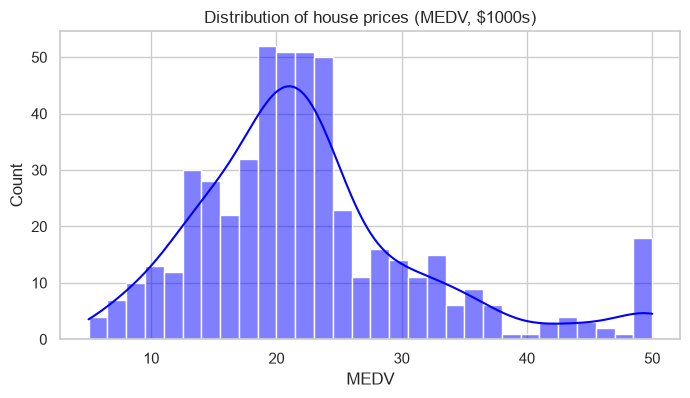

In [32]:
print(df["MEDV"].describe().round(2))
print("Homes priced at exactly 50:", (df["MEDV"] == 50).sum())

plt.figure(figsize=(8, 4))
sns.histplot(df["MEDV"], bins=30, kde=True, color="blue")
plt.title("Distribution of house prices (MEDV, $1000s)")
plt.show()

**Interpretation:** The average price is about 22.5 and the median is 21.2 (in thousands of dollars), so most homes are in the low 20s, with a tail of expensive homes pulling the average up. Prices run from 5 to 50. Sixteen homes sit at exactly 50, which looks like a cap in the data (the true price of those homes may be higher). I expect every model to underestimate the most expensive homes because of this.

### 2.4 Which Features Relate to Price?

LSTAT     -0.74
PTRATIO   -0.51
INDUS     -0.48
TAX       -0.47
NOX       -0.43
CRIM      -0.39
RAD       -0.38
AGE       -0.38
CHAS       0.18
DIS        0.25
ZN         0.36
RM         0.70
Name: MEDV, dtype: float64


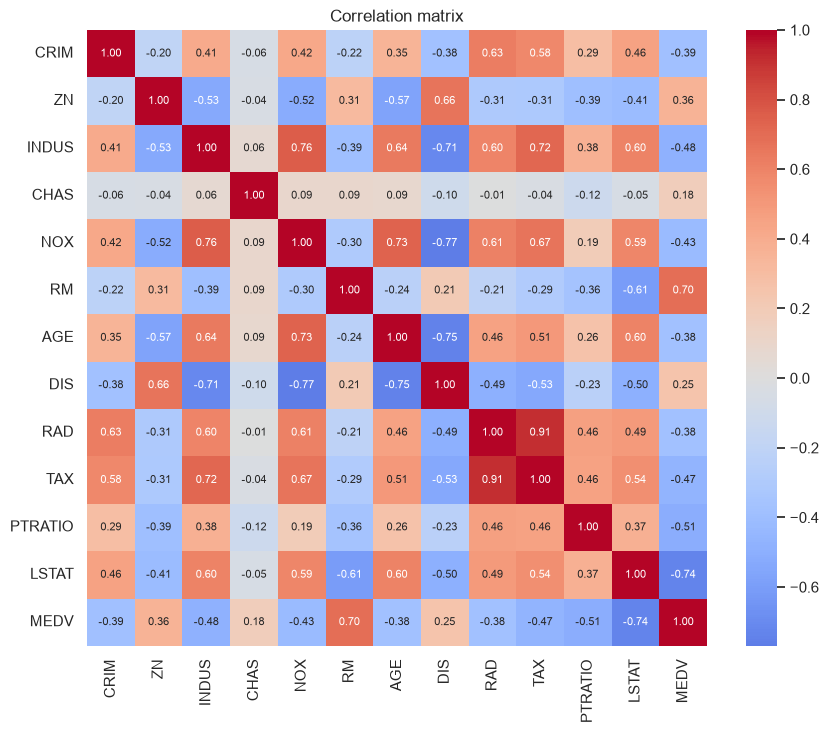

In [34]:
corr = df.corr()
print(corr["MEDV"].drop("MEDV").sort_values().round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Correlation matrix")
plt.show()

**Interpretation:** Two features stand out. `LSTAT` (percentage of lower-status residents) has the strongest link with price at -0.74: the higher it is, the lower the price. `RM` (average rooms) is next at +0.70: more rooms, higher price. `PTRATIO` (-0.51) is the next strongest. The remaining features have weaker links of 0.4 or less. This tells me `RM` and `LSTAT` will probably matter most in the models.

### 2.5 Scatter Plots of the Two Strongest Features

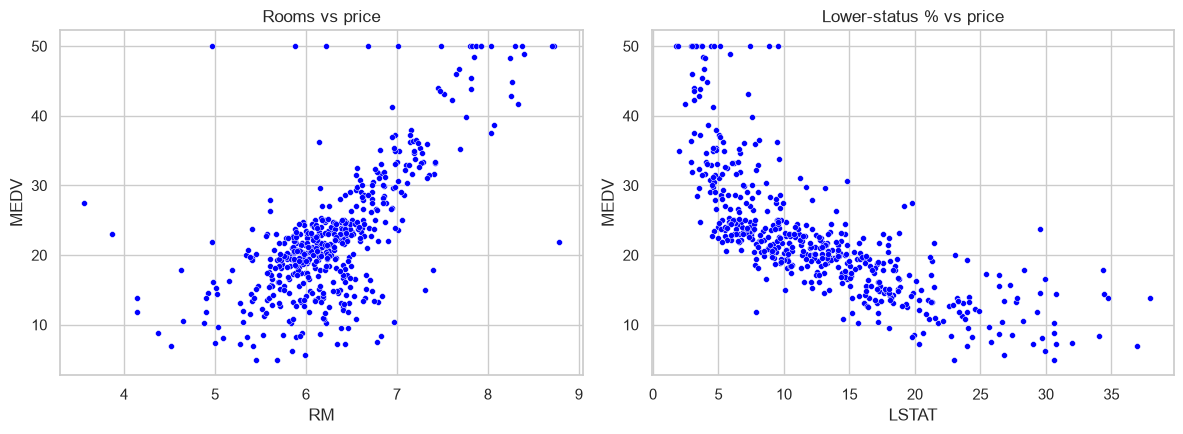

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x="RM", y="MEDV", data=df, ax=axes[0], color="blue", s=18)
axes[0].set_title("Rooms vs price")
sns.scatterplot(x="LSTAT", y="MEDV", data=df, ax=axes[1], color="blue", s=18)
axes[1].set_title("Lower-status % vs price")
plt.tight_layout()
plt.show()

**Interpretation:** The rooms plot shows a fairly straight upward trend, with a row of dots at the top that are the capped 50 values. The `LSTAT` plot is different: price drops quickly at first and then flattens out, so the pattern is a curve, not a straight line. A linear regression can only draw straight lines, so I expect it to struggle with this feature, while Decision Trees and Random Forests can follow curves.

## 3.0 Splitting and Scaling the Data

### 3.1 Train/Test Split

In [36]:
X = df.drop(columns="MEDV")     # features
y = df["MEDV"]                  # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (404, 12)
Testing set : (102, 12)


**Interpretation:** I used 80% of the houses for training (404) and kept 20% (102) for testing. The test houses are not shown to the model while it learns, so the test score tells me how well it predicts houses it has never seen. `random_state=42` makes the split the same every time I run the notebook.

### 3.2 Scaling the Features

In [37]:
# the scaler learns its mean and spread from the training set only
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Mean of scaled training features (should be about 0):", X_train_s.mean().round(3))

Mean of scaled training features (should be about 0): -0.0


**Interpretation:** I fitted the scaler on the training set only and then applied the same scaling to the test set. If the scaler had seen the test data, some information from the test set would leak into training. Scaling mainly helps me compare the linear regression coefficients on the same footing. The tree models do not need it, so I use the unscaled data for them.

## 4.0 Linear Regression

### 4.1 Training the Model

In [38]:
lin = LinearRegression()
lin.fit(X_train_s, y_train)

pred_train = lin.predict(X_train_s)
pred_test = lin.predict(X_test_s)
print("Intercept:", round(lin.intercept_, 2))

Intercept: 22.8


**Interpretation:** The model is trained. The intercept of 22.8 is close to the average house price, which is what I expect: with scaled features, the intercept is the prediction for an average house.

### 4.2 Evaluating with MSE and R-squared

In [39]:
def scores(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

lin_train = scores(y_train, pred_train)
lin_test = scores(y_test, pred_test)
pd.DataFrame({"Train": lin_train, "Test": lin_test}).round(3)

,Train,Test
MSE,22.604,22.778
RMSE,4.754,4.773
R2,0.740,0.689


**Interpretation:** On the test set the model has an MSE of 22.78 and an RMSE of 4.77, so its typical error is about 4.8 thousand dollars. R-squared is 0.69, meaning the model explains about 69% of the differences in house prices. The training scores (R-squared 0.74, MSE 22.60) are close to the test scores, so the model is not overfitting. It is simply limited, which supports what I saw in the scatter plots: a straight-line model cannot capture everything here.

### 4.3 Actual vs Predicted Prices and Residuals

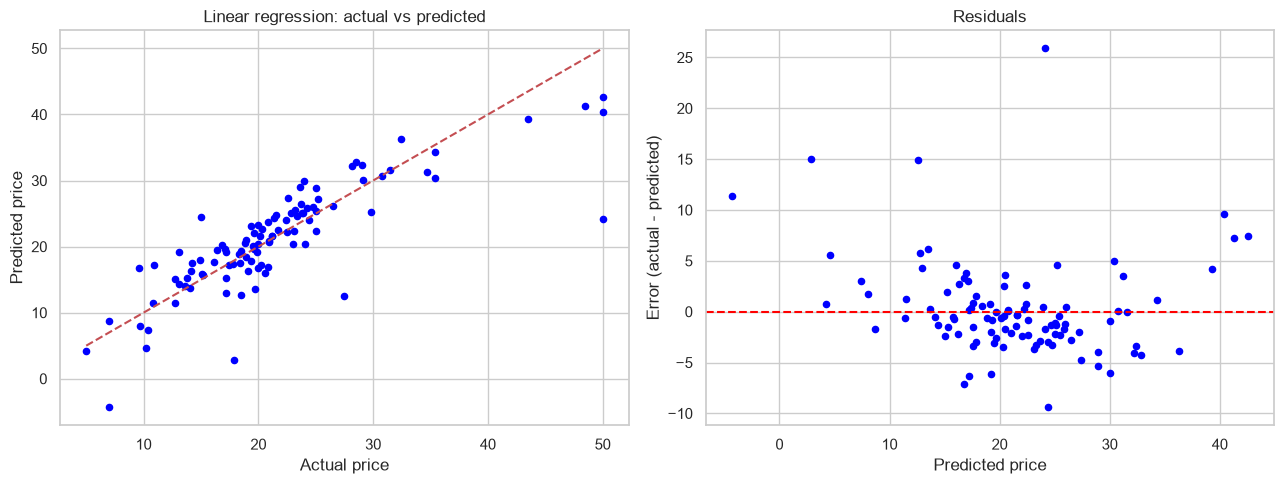

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, pred_test, s=20, color="blue")
axes[0].plot([5, 50], [5, 50], "r--")        # perfect predictions would sit on this line
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
axes[0].set_title("Linear regression: actual vs predicted")

residuals = y_test - pred_test
axes[1].scatter(pred_test, residuals, s=20, color="blue")
axes[1].axhline(0, color="red", ls="--")
axes[1].set_xlabel("Predicted price")
axes[1].set_ylabel("Error (actual - predicted)")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

**Interpretation:** In the left plot the dots follow the red line in the middle, but they drift away at both ends. The model underestimates the expensive homes (the ones at 50), and it even predicts a negative price for one house, which is impossible. In the right plot, a good model would show errors scattered randomly around zero. Here they form a curve (positive at the low and high ends, negative in the middle), which tells me the relationship is not a straight line, as I suspected.

### 4.4 Which Features Matter Most in the Linear Model?

LSTAT     -3.82
DIS       -3.12
NOX       -2.14
PTRATIO   -1.99
TAX       -1.87
CRIM      -1.13
AGE       -0.10
INDUS      0.17
ZN         0.71
CHAS       0.79
RAD        2.06
RM         3.00
dtype: float64


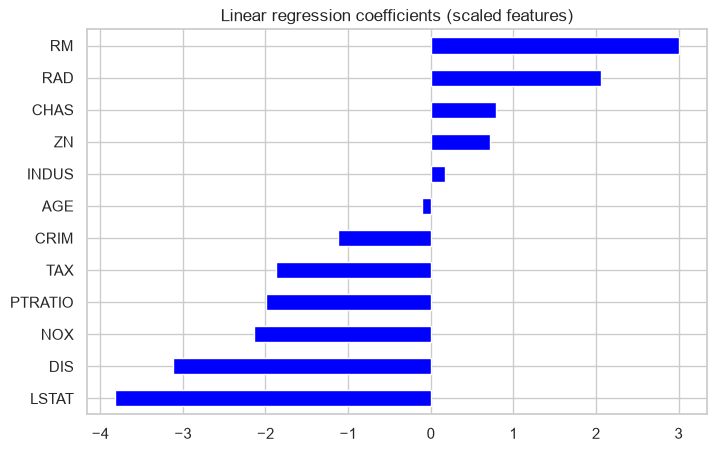

In [42]:
coefs = pd.Series(lin.coef_, index=X.columns).sort_values()
print(coefs.round(2))

coefs.plot(kind="barh", color="blue", figsize=(8, 5))
plt.title("Linear regression coefficients (scaled features)")
plt.show()

**Interpretation:** `LSTAT` (-3.82), `DIS` (-3.12) and `RM` (+3.00) have the biggest effect. Each number is the change in price (in thousands of dollars) when that feature goes up by one standard deviation, with the others held constant. A higher lower-status share and a greater distance from employment centres lower the price, and more rooms raise it. `NOX`, `PTRATIO` and `TAX` also push prices down. `AGE`, `INDUS`, `ZN` and `CHAS` have small effects once the other features are in the model.

## 5.0 Trying Other Models

### 5.1 Decision Tree

In [25]:
tree_full = DecisionTreeRegressor(random_state=42)      # no depth limit
tree_full.fit(X_train, y_train)

tree = DecisionTreeRegressor(max_depth=5, random_state=42)   # limited to 5 levels
tree.fit(X_train, y_train)

for name, m in [("Tree, no limit", tree_full), ("Tree, max_depth=5", tree)]:
    print(f"{name}: train R2 = {r2_score(y_train, m.predict(X_train)):.3f}, "
          f"test R2 = {r2_score(y_test, m.predict(X_test)):.3f}")

Tree, no limit: train R2 = 1.000, test R2 = 0.878
Tree, max_depth=5: train R2 = 0.918, test R2 = 0.879


**Interpretation:** The tree with no depth limit scores a perfect 1.000 on the training data, which means it memorised the training houses, but only 0.878 on the test data. That gap is overfitting. When I limited it to 5 levels, the training score dropped to 0.918 and the test score stayed at 0.879. So the simpler tree predicts just as well on new houses and does not memorise.

### 5.2 Random Forest

In [26]:
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

print(f"Random Forest: train R2 = {r2_score(y_train, rf.predict(X_train)):.3f}, "
      f"test R2 = {r2_score(y_test, rf.predict(X_test)):.3f}")

Random Forest: train R2 = 0.978, test R2 = 0.881


**Interpretation:** The Random Forest scores 0.978 on training data and 0.881 on test data. It averages 200 trees, which makes it more stable than a single tree. It also fits the training data very closely, but the test score is what counts.

### 5.3 Comparing All the Models

In [27]:
results = {
    "Linear Regression": (y_train, pred_train, y_test, pred_test),
    "Decision Tree (depth 5)": (y_train, tree.predict(X_train), y_test, tree.predict(X_test)),
    "Random Forest": (y_train, rf.predict(X_train), y_test, rf.predict(X_test)),
}

rows = []
for name, (yt, ypt, ys, yps) in results.items():
    rows.append({"Model": name,
                 "Train R2": r2_score(yt, ypt),
                 "Test R2": r2_score(ys, yps),
                 "Test MSE": mean_squared_error(ys, yps),
                 "Test RMSE": np.sqrt(mean_squared_error(ys, yps))})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Train R2,Test R2,Test MSE,Test RMSE
Model,,,,
Linear Regression,0.740,0.689,22.778,4.773
Decision Tree (depth 5),0.918,0.879,8.846,2.974
Random Forest,0.978,0.881,8.721,2.953


**Interpretation:** Both tree-based models do much better than linear regression. Test R-squared goes from 0.689 to about 0.88, and the test MSE falls from 22.78 to about 8.8, around 60% lower. The Random Forest is best (MSE 8.72, RMSE 2.95), but on this one split it is only slightly ahead of the depth-5 tree. The curve in the data is the reason linear regression loses: the trees can bend to fit it.

### 5.4 Visual Comparison

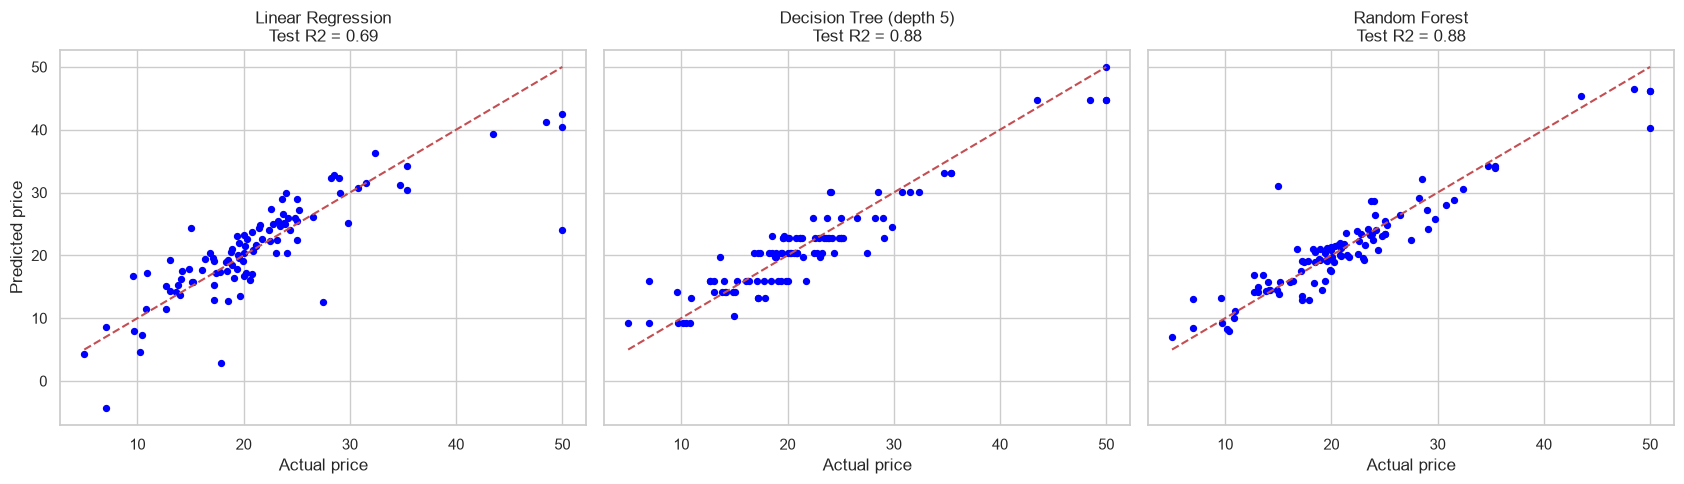

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, (name, (yt, ypt, ys, yps)) in zip(axes, results.items()):
    ax.scatter(ys, yps, s=18, color="blue")
    ax.plot([5, 50], [5, 50], "r--")
    ax.set_title(f"{name}\nTest R2 = {r2_score(ys, yps):.2f}")
    ax.set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
plt.tight_layout()
plt.show()

**Interpretation:** The linear regression dots are widely scattered around the red line, especially at the ends. The Decision Tree dots are tighter, but they form horizontal rows because a tree predicts the same value for every house that lands in the same group. The Random Forest dots are the tightest and smoothest, because averaging many trees blends those steps together.

## 6.0 Feature Importance in the Random Forest

### 6.1 Which Features Does the Best Model Use?

RM         0.494
LSTAT      0.327
DIS        0.056
CRIM       0.042
PTRATIO    0.017
TAX        0.016
AGE        0.016
NOX        0.016
INDUS      0.007
RAD        0.005
ZN         0.002
CHAS       0.001
dtype: float64


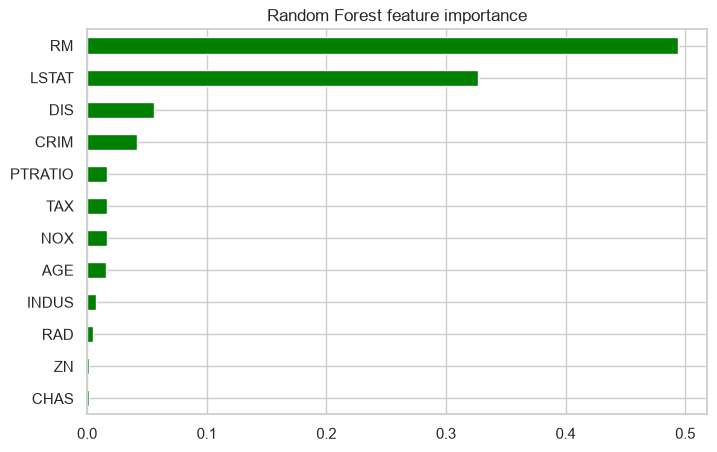

In [44]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
print(importance.round(3).sort_values(ascending=False))

importance.plot(kind="barh", color="green", figsize=(8, 5))
plt.title("Random Forest feature importance")
plt.show()

**Interpretation:** `RM` (0.49) and `LSTAT` (0.33) together make up about 82% of the forest's decisions. `DIS` (0.06) and `CRIM` (0.04) come next, and the rest barely matter. This agrees with the correlations and scatter plots from section 2: the number of rooms and the lower-status share are what drive house prices in this data.

## 7.0 Checking the Results with Cross-Validation

### 7.1 Five-Fold Cross-Validation

In [30]:
# one split can be lucky or unlucky, so I repeat the test on 5 different splits
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree (depth 5)": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

cv_rows = {}
for name, model in models.items():
    s = cross_val_score(model, X, y, cv=kf, scoring="r2")
    cv_rows[name] = {"Mean R2": s.mean(), "Std": s.std(), "Lowest fold": s.min(), "Highest fold": s.max()}
pd.DataFrame(cv_rows).T.round(3)

,Mean R2,Std,Lowest fold,Highest fold
Linear Regression,0.712,0.031,0.676,0.766
Decision Tree (depth 5),0.761,0.121,0.531,0.879
Random Forest,0.870,0.031,0.816,0.907


**Interpretation:** This check shows something the single split hid. On one split, the depth-5 tree (0.879) looked as good as the Random Forest (0.881). Across five splits, the Random Forest averages 0.870 with a small spread (0.816 to 0.907), while the tree averages only 0.761 and swings from 0.531 to 0.879. So the tree was lucky on my first split, and the Random Forest is the reliable choice. Linear regression is steady (0.712 on average) but clearly lower. The forest's cross-validated score (0.870) is also close to its test score (0.881), which gives me confidence that the result is real.

## 8.0 Does Dropping the B Column Change the Results

### 8.1 Comparing the Models With and Without B

In [45]:
# same 5 splits as in 7.1, so the two versions are compared fairly
def cv_r2(data, model):
    return cross_val_score(model, data.drop(columns="MEDV"), data["MEDV"], cv=kf, scoring="r2").mean()

def make_models():
    return {"Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
            "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42)}

check = pd.DataFrame({
    "With B": {name: cv_r2(df_with_b, m) for name, m in make_models().items()},
    "Without B": {name: cv_r2(df, m) for name, m in make_models().items()},
})
check["Difference"] = check["With B"] - check["Without B"]
check.round(3)

,With B,Without B,Difference
Linear Regression,0.715,0.712,0.003
Random Forest,0.870,0.870,-0.000


**Interpretation:** Keeping `B` makes almost no difference. Linear regression scores an R-squared of 0.715 with `B` and 0.712 without it (a difference of 0.003), and the Random Forest scores 0.870 either way. So removing `B` costs essentially no accuracy, because the other features, mainly `RM` and `LSTAT`, already carry the useful information. This supports my decision in 2.2: I gave up almost nothing and avoided a feature built on the racial makeup of a neighbourhood.

## 9.0 Conclusion

### 9.1 Results
| Model | Test R-squared | Test MSE | Test RMSE | Cross-validated R-squared |
|---|---|---|---|---|
| Linear Regression | 0.689 | 22.78 | 4.77 | 0.712 |
| Decision Tree (depth 5) | 0.879 | 8.85 | 2.97 | 0.761 |
| **Random Forest** | **0.881** | **8.72** | **2.95** | **0.870** |

### 9.2 What I Found
1. **The Random Forest is the best model.** It explains about 88% of house price differences, and its typical error is about 3 thousand dollars, compared with 4.8 thousand for linear regression.
2. **Linear regression is limited here** because house prices do not rise and fall in a straight line with features like `LSTAT`.
3. **A single train/test split can mislead.** The Decision Tree looked as good as the forest on one split, but cross-validation showed it is much less stable.
4. **The number of rooms (`RM`) and the share of lower-status residents (`LSTAT`) drive prices.** Together they make up about 82% of the Random Forest's decisions.

### 9.3 Limitations
- House prices are capped at 50, so the models underestimate the most expensive homes.
- I removed the `B` column for ethical reasons (see 2.2) and showed in 8.1 that this costs almost no accuracy. I did not tune any model settings.
- The dataset is old (1970s Boston-area data), so these results should not be used to value homes today.

### 9.4 Possible Next Steps
Tune the Random Forest settings (number of trees, depth), try gradient boosting, and test whether transforming the price (for example with a log) helps linear regression.